In [ ]:
# %pip install Seaborn
# %pip install plotly
# %pip install pandas
# %pip install numpy
# %pip install matplotlib

In [5]:
import plotly.express as px
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv("social_media_engagement_5000.csv")

In [7]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [8]:
df.shape

(5000, 19)

In [9]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [11]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y", errors="coerce")


In [12]:
numeric_columns = [
    "age", "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [13]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [14]:
likes_array = df["likes"].to_numpy()

NumPy likes array (first 10)

In [15]:
likes_array[:10]

array([ 7011., 11750.,  4862.,  5350., 12682., 12535., 11703.,  9611.,
          nan, 14106.])

Number of non-missing like values

In [16]:
np.count_nonzero(~np.isnan(likes_array))

np.int64(4850)

Mean likes using NumPy

In [17]:
np.nanmean(likes_array)

np.float64(10107.043711340206)

Maximum likes using NumPy

In [18]:
np.nanmax(likes_array)

np.float64(19998.0)

# Task 2 — Data Cleaning

Finding missing values

In [19]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [20]:
df.isna().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Checking for duplicates

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df = df.drop_duplicates()

In [23]:
df = df.dropna(
    subset=["user_id", "post_id", "posted_at"]
)

Standardise text

In [24]:
text_columns = [
    "gender", "country", "post_type", "post_category",
    "device_type", "sentiment", "hashtags"
]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip()

In [25]:
df["gender"] = df["gender"].str.title()
df["country"] = df["country"].str.title()

df["post_type"] = df["post_type"].str.lower()
df["post_category"] = df["post_category"].str.lower()
df["device_type"] = df["device_type"].str.lower()

In [26]:
df["sentiment"] = (
    df["sentiment"].str.lower()
    .str.replace(r"[^a-z\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [27]:
sentiment_map = {
    "positive": "positive", 
    "pos": "positive",
    "neutral": "neutral", 
    "neu": "neutral",
    "negative": "negative", 
    "neg": "negative"
}

df["sentiment"] = (
    df["sentiment"].map(sentiment_map).fillna(df["sentiment"])
)

In [28]:
engagement_counts = ["likes", "comments", "shares"]

for column in engagement_counts:
    df.loc[df[column] < 0, column] = np.nan

In [29]:
numeric_to_impute = [
    "age", "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate"
]

for column in numeric_to_impute:
    df[column] = df[column].fillna(df[column].median())

In [30]:
categorical_to_impute = [
    "gender", "sentiment", "country", "post_type",
    "post_category", "device_type", "hashtags"
]

for column in categorical_to_impute:
    modes = df[column].mode(dropna=True)

    if not modes.empty:
        df[column] = df[column].fillna(modes.iloc[0])

In [31]:
df["hashtags"] = df["hashtags"].fillna("").astype(str).str.strip()
df["hashtag_count"] = df["hashtags"].str.count("#")
df[["hashtags", "hashtag_count"]].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [32]:
df.duplicated().sum()

np.int64(0)

In [33]:
df[["age", "likes", "comments", "shares"]]= df[["age", "likes", "comments", "shares"]].astype("int64")

In [34]:
df.dtypes

user_id                      int64
age                          int64
gender                      string
country                     string
post_id                      int64
post_type                   string
post_category               string
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                 string
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [35]:
df.isna().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64

In [36]:
for column in engagement_counts:
    print(column, int((df[column] < 0).sum()))

likes 0
comments 0
shares 0


# ❖	Task 3 — Data Exploration using Pandas

In [37]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [38]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [39]:
df.shape

(5000, 20)

In [40]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   string        
 3   country           5000 non-null   string        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   string        
 6   post_category     5000 non-null   string        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [42]:
df.dtypes

user_id                      int64
age                          int64
gender                      string
country                     string
post_id                      int64
post_type                   string
post_category               string
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                 string
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [43]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [44]:
categorical_columns = [
    "gender", "country", "post_type", "post_category",
    "is_verified", "device_type", "sentiment"
]
for column in categorical_columns:
    print(f"\n{column}: value_counts")
    print(df[column].value_counts(dropna=False))
    print("Unique values:", df[column].unique())
    print("Number of unique values:", df[column].nunique(dropna=False))


gender: value_counts
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: Int64
Unique values: <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: string
Number of unique values: 3

country: value_counts
country
India        535
Canada       513
Brazil       504
Uae          503
Usa          501
France       496
Uk           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: Int64
Unique values: <StringArray>
[   'Brazil',        'Uk',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'Uae',   'Germany',       'Usa']
Length: 10, dtype: string
Number of unique values: 10

post_type: value_counts
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: Int64
Unique values: <StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: string
Number of unique values: 4

post_category: value_counts
post_category
fitness      675
tech         665
music        635
education    631
lifes

In [45]:
numeric_fields = df.select_dtypes(include=np.number).columns.tolist()

correlation_matrix = df[numeric_fields].corr(numeric_only=True)
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [46]:
print("\nAverage likes by post type")
display(df.groupby("post_type", as_index=False)["likes"].mean()
        .rename(columns={"likes": "avg_likes"}).sort_values("avg_likes", ascending=False))



Average likes by post type


,post_type,avg_likes
3,video,10188.586122
0,image,10104.852446
2,text,10100.132530
1,reel,10037.784879


In [47]:
print("\nAverage impressions by country (top 10)")
display(df.groupby("country", as_index=False)["impression_count"].mean()
        .rename(columns={"impression_count": "avg_impressions"})
        .sort_values("avg_impressions", ascending=False).head(10))


Average impressions by country (top 10)


,country,avg_impressions
5,India,52462.386916
3,France,51727.673387
9,Usa,51263.872255
8,Uk,51119.393509
6,Japan,49616.135593
1,Brazil,49193.174603
7,Uae,48928.413519
2,Canada,48703.150097
4,Germany,48605.406122
0,Australia,48346.383367


# ❖	Task 4 — Data Wrangling 

In [48]:
midpoint = len(df) // 2

df_first = df.iloc[:midpoint].copy()
df_second = df.iloc[midpoint:].copy()

df_combined = pd.concat(
    [df_first, df_second],
    ignore_index=True
)

In [49]:
df["engagement_score"] = df[
    ["likes", "comments", "shares"]
].sum(axis=1)

In [50]:
print("\nSummary by post_type")
display(df.groupby("post_type").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_impressions=("impression_count", "mean")
).sort_values("avg_engagement_score", ascending=False).round(3))

print("\nSummary by country (top 10 by average engagement rate)")
display(df.groupby("country").agg(
    posts=("post_id", "count"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_engagement_score=("engagement_score", "mean")
).sort_values("avg_engagement_rate", ascending=False).head(10).round(3))

print("\nSummary by sentiment")
display(df.groupby("sentiment").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean")
).sort_values("avg_engagement_score", ascending=False).round(3))


Summary by post_type


,posts,avg_engagement_score,avg_engagement_rate,avg_likes,avg_impressions
post_type,,,,,
video,1225,12664.580,1.122,10188.586,49862.015
image,1247,12649.378,0.896,10104.852,49727.422
text,1245,12613.228,1.065,10100.133,49987.218
reel,1283,12524.014,0.783,10037.785,50462.599



Summary by country (top 10 by average engagement rate)


,posts,avg_engagement_rate,avg_engagement_score
country,,,
Brazil,504,1.541,12385.972
Australia,493,1.324,12809.604
France,496,1.146,12903.371
Uae,503,1.112,12757.763
Canada,513,0.917,12605.883
Uk,493,0.851,12384.361
Japan,472,0.770,12578.638
Germany,490,0.759,12635.641
India,535,0.655,12492.679



Summary by sentiment


,posts,avg_engagement_score,avg_engagement_rate,avg_likes,avg_comments,avg_shares
sentiment,,,,,,
negative,960,12731.483,1.038,10208.081,1516.095,1007.307
positive,2513,12665.784,0.920,10180.047,1480.651,1005.087
neutral,1527,12448.149,0.991,9923.180,1528.404,996.565


# ❖	Task 5 — Statistical Analysis 

In [51]:
stats_fields = [
    "likes", "comments", "shares", "watch_time_sec",
    "engagement_rate", "follower_count"
]

stat_rows = []
for column in stats_fields:
    series = df[column].dropna()
    modes = series.mode()
    stat_rows.append({
        "metric": column,
        "mean": series.mean(),
        "median": series.median(),
        "mode": modes.iloc[0] if not modes.empty else np.nan,
        "std_dev": series.std(),
        "variance": series.var(),
        "p25": series.quantile(0.25),
        "p50": series.quantile(0.50),
        "p75": series.quantile(0.75),
        "p90": series.quantile(0.90),
        "skewness": series.skew(),
        "kurtosis": series.kurt()
    })

statistics_table = pd.DataFrame(stat_rows).set_index("metric")
display(statistics_table.round(3))

,mean,median,mode,std_dev,variance,p25,p50,p75,p90,skewness,kurtosis
metric,,,,,,,,,,,
likes,10106.982,10105.000,10105.000,5702.293,3.251615e+07,5235.000,10105.000,14959.000,18016.300,-0.007,-1.150
comments,1502.040,1497.000,1497.000,856.393,7.334095e+05,792.000,1497.000,2235.250,2695.100,0.004,-1.144
shares,1002.911,1012.000,1012.000,570.855,3.258757e+05,511.000,1012.000,1483.000,1795.100,-0.015,-1.147
watch_time_sec,4014.503,4034.500,916.000,2308.096,5.327309e+06,2017.750,4034.500,6020.250,7212.100,-0.018,-1.196
engagement_rate,0.964,0.254,0.006,5.318,2.828100e+01,0.146,0.254,0.505,1.201,18.781,482.992
follower_count,393698.225,388982.000,497502.000,230927.885,5.332769e+10,194480.000,388982.000,589744.250,717755.900,0.041,-1.189


# ❖	Task 6 — Data Visualization 

In [52]:
sns.set_theme(style="whitegrid")


 1. Scatter: likes vs impressions

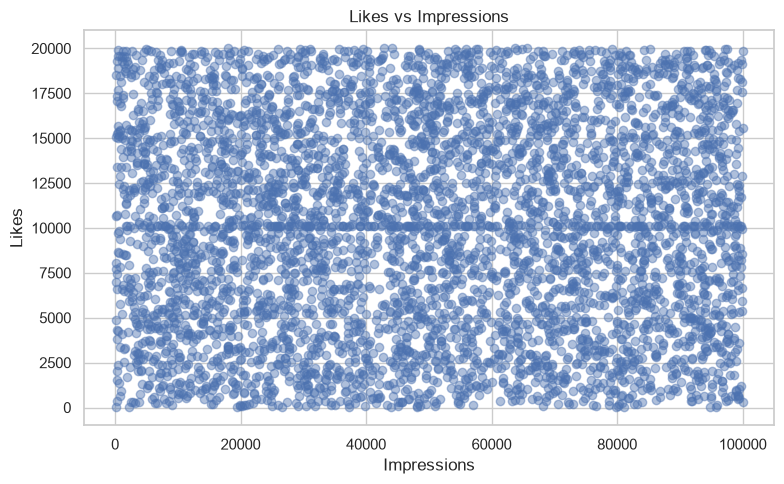

In [53]:
plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], alpha=0.45)
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.tight_layout()
plt.show()

2. Line: daily engagement trend

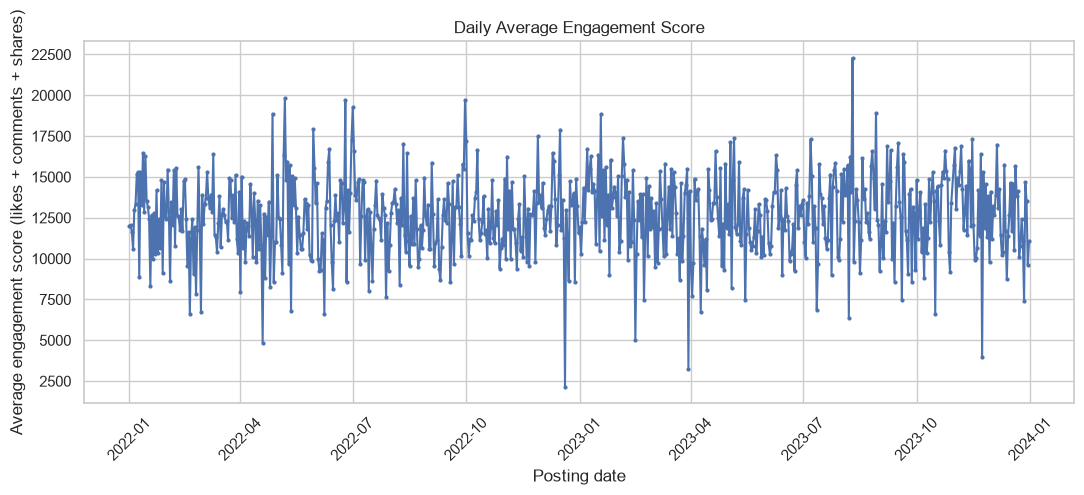

In [54]:
daily_engagement = df.groupby(df["posted_at"].dt.date)["engagement_score"].mean().sort_index()
plt.figure(figsize=(11, 5))
plt.plot(pd.to_datetime(daily_engagement.index), daily_engagement.values, marker="o", markersize=2)
plt.title("Daily Average Engagement Score")
plt.xlabel("Posting date")
plt.ylabel("Average engagement score (likes + comments + shares)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Bar: posts by category

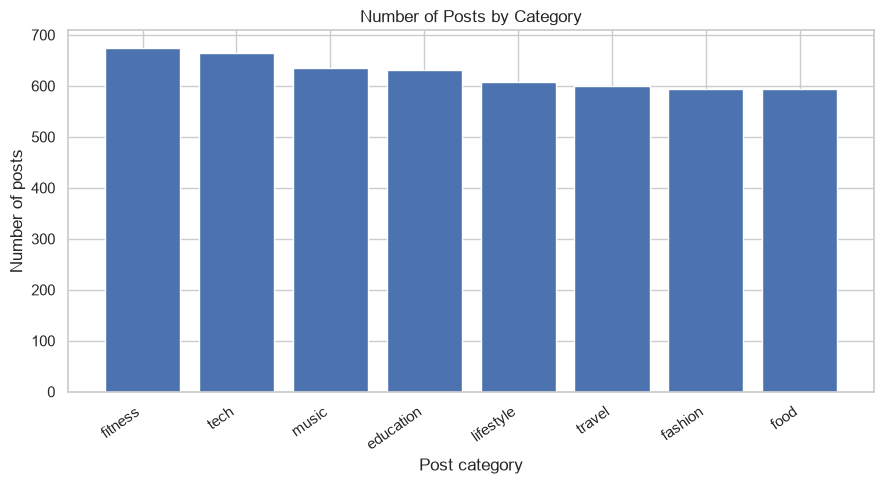

In [55]:
posts_by_category = df["post_category"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
plt.bar(posts_by_category.index, posts_by_category.values)
plt.title("Number of Posts by Category")
plt.xlabel("Post category")
plt.ylabel("Number of posts")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

4. Pie: gender distribution

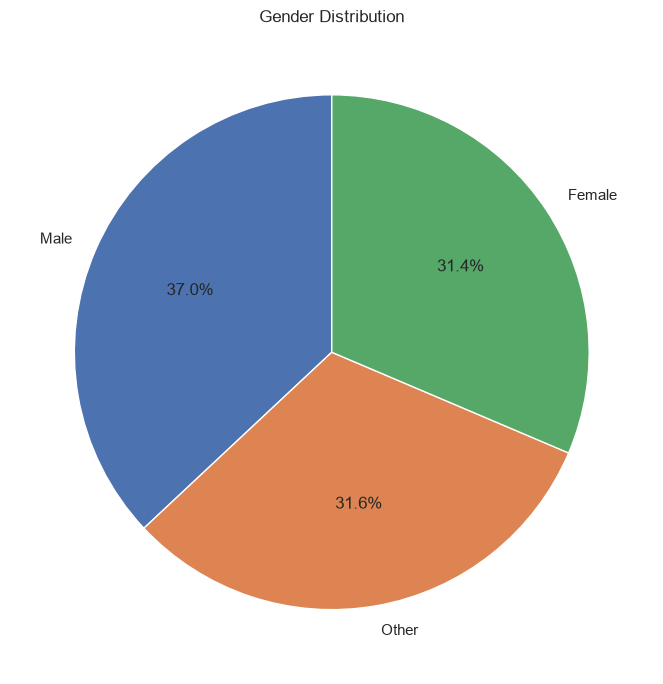

In [56]:
gender_counts = df["gender"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

5. Histogram: age

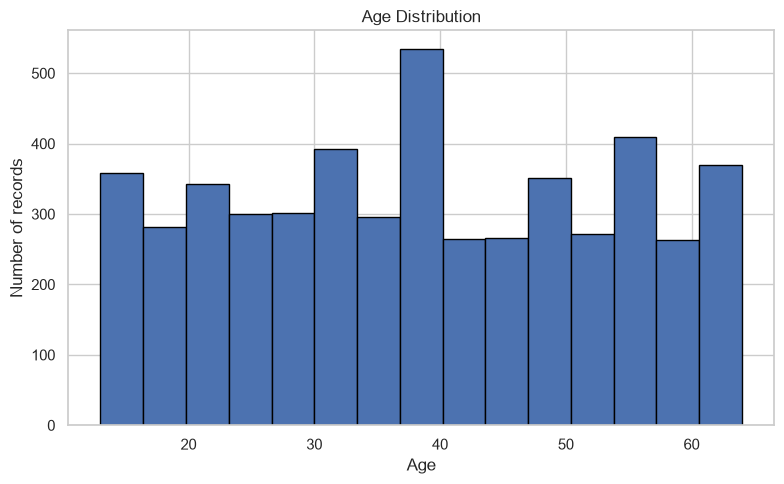

In [57]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


6. Box: engagement rate

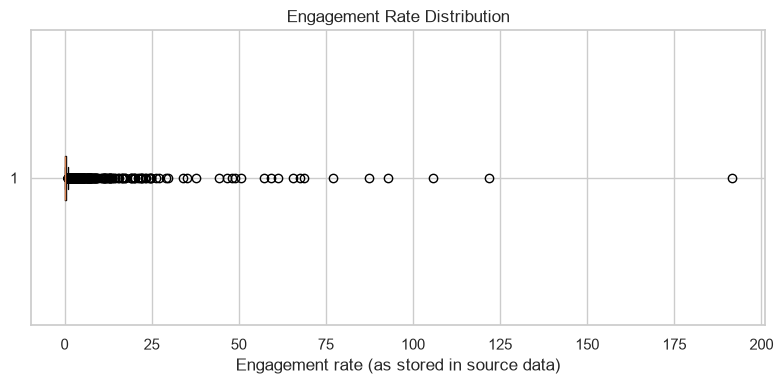

In [58]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["engagement_rate"], orientation='horizontal')
plt.title("Engagement Rate Distribution")
plt.xlabel("Engagement rate (as stored in source data)")
plt.tight_layout()
plt.show()

7. Count plot: post type

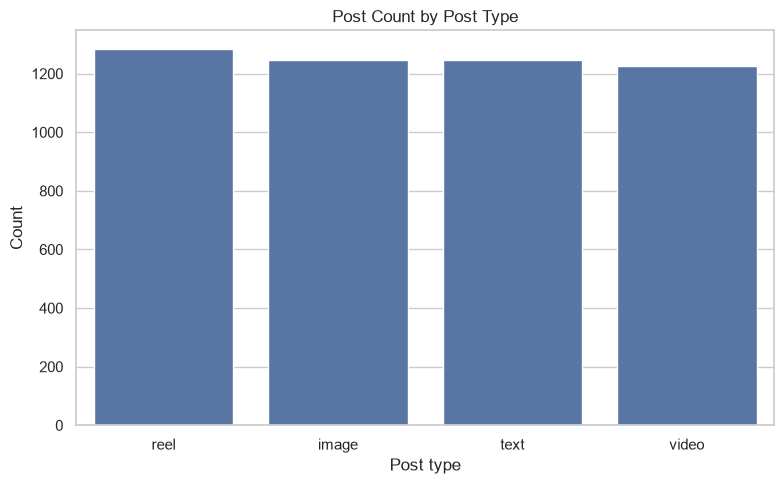

In [59]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type", order=df["post_type"].value_counts().index)
plt.title("Post Count by Post Type")
plt.xlabel("Post type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

8. Bar plot: average likes by category

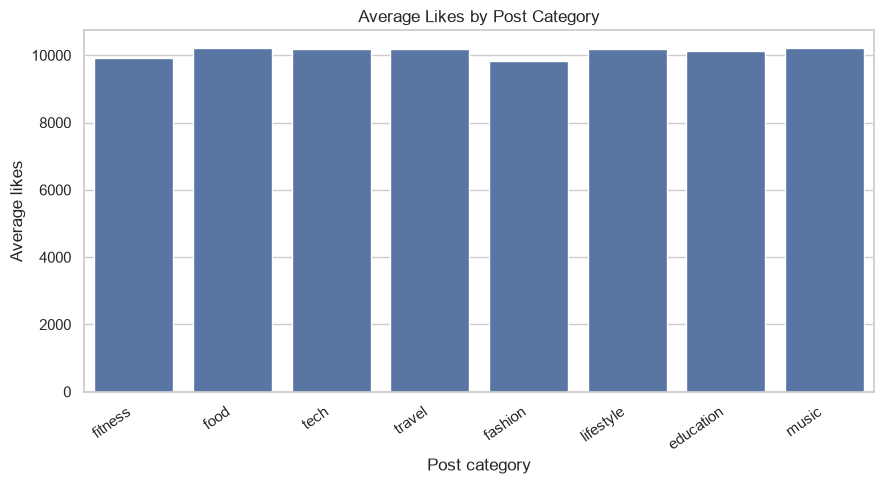

In [60]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="post_category", y="likes", estimator=np.mean, errorbar=None)
plt.title("Average Likes by Post Category")
plt.xlabel("Post category")
plt.ylabel("Average likes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

9. Violin: followers vs sentiment (sample to keep rendering manageable)

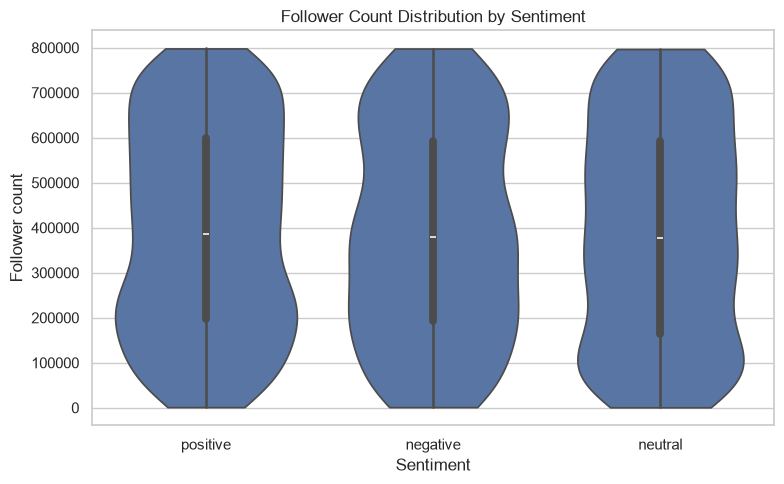

In [61]:
violin_sample = df.sample(n=min(1500, len(df)), random_state=42)
plt.figure(figsize=(8, 5))
sns.violinplot(data=violin_sample, x="sentiment", y="follower_count", cut=0)
plt.title("Follower Count Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower count")
plt.tight_layout()
plt.show()

10. Pair plot: numeric features (sampled for readability/performance)

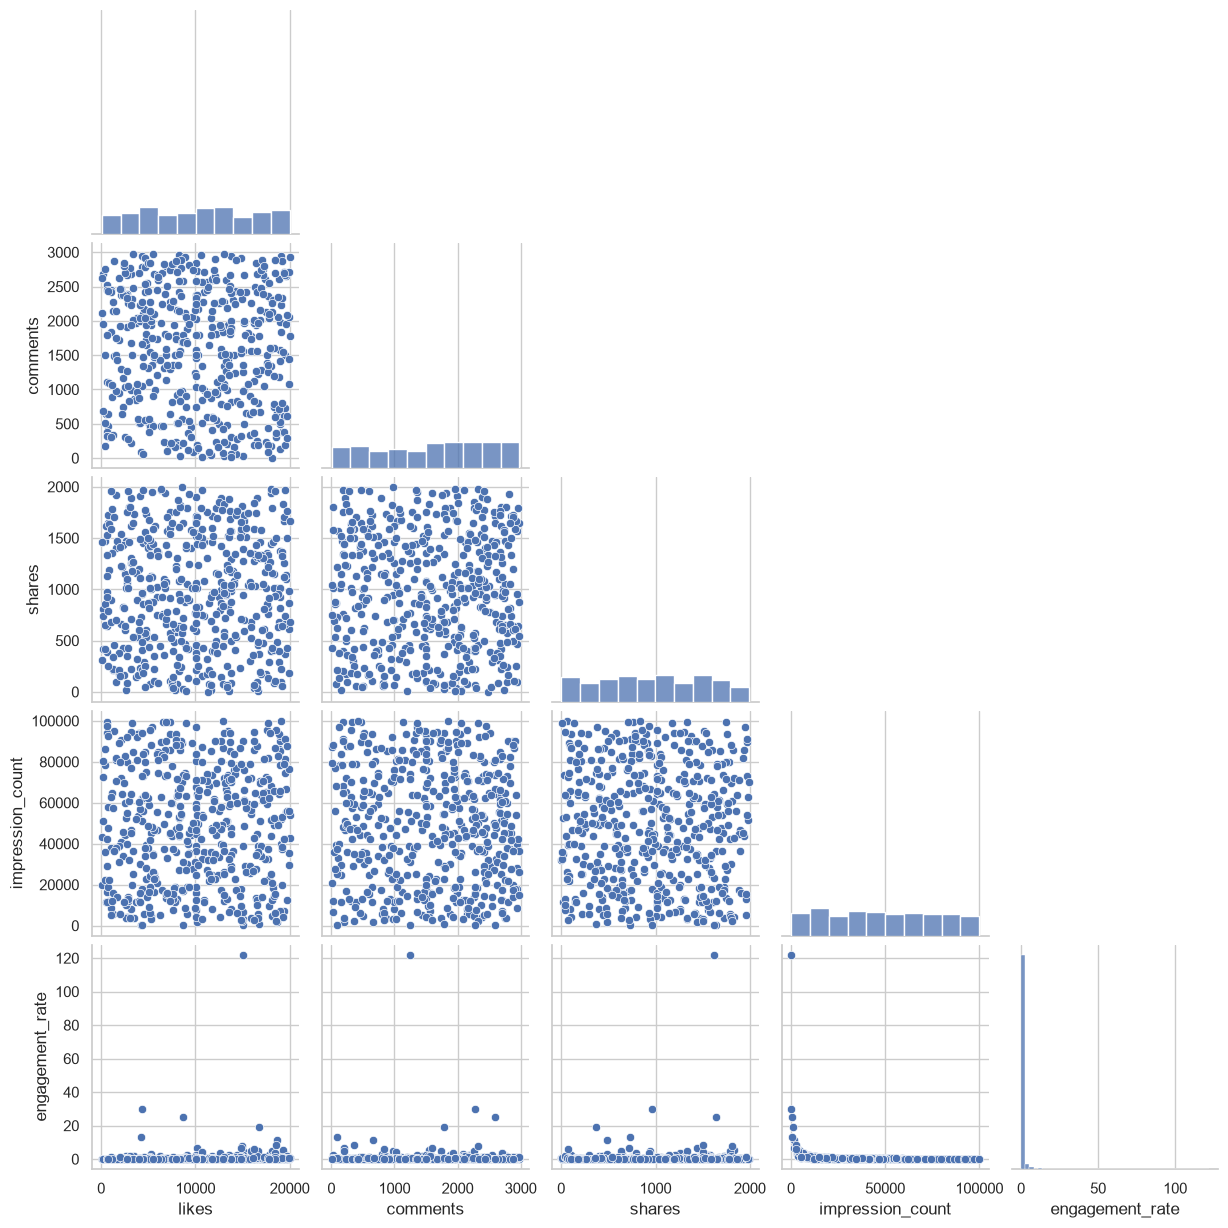

In [62]:
pair_fields = ["likes", "comments", "shares", "impression_count", "engagement_rate"]
pair_sample = df[pair_fields].sample(n=min(500, len(df)), random_state=42)
sns.pairplot(pair_sample, diag_kind="hist", corner=True)
plt.show()

11. Heatmap: correlation matrix for numeric fields

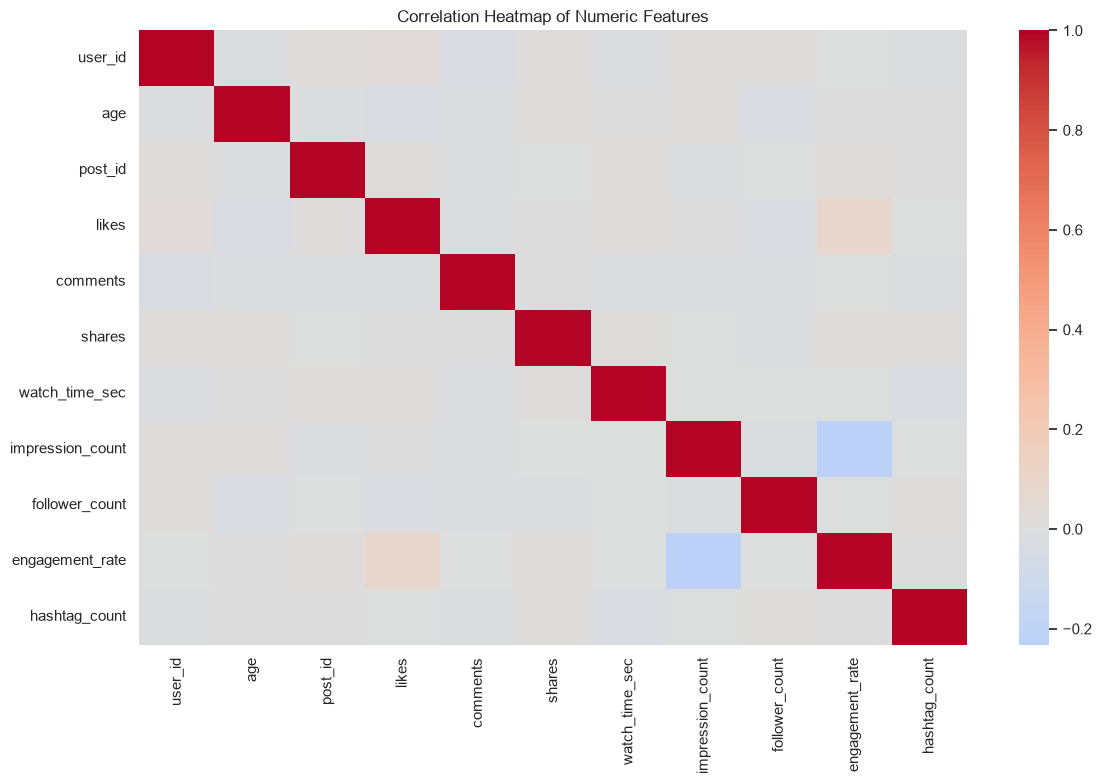

In [63]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

12. Swarm plot: engagement vs device

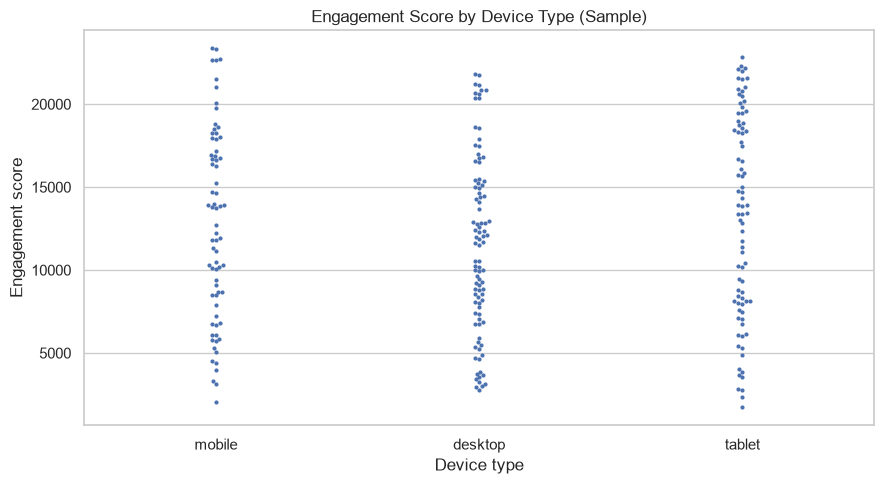

In [64]:
swarm_sample = df.sample(n=min(250, len(df)), random_state=42)
plt.figure(figsize=(9, 5))
sns.swarmplot(data=swarm_sample, x="device_type", y="engagement_score", size=3)
plt.title("Engagement Score by Device Type (Sample)")
plt.xlabel("Device type")
plt.ylabel("Engagement score")
plt.tight_layout()
plt.show()

Plotly interactive chart

In [65]:
#%pip install --upgrade nbformat

In [66]:
plotly_daily = daily_engagement.reset_index()
plotly_daily.columns = ["posted_at", "avg_engagement_score"]
plotly_daily["posted_at"] = pd.to_datetime(plotly_daily["posted_at"])

fig = px.line(
    plotly_daily,
    x="posted_at",
    y="avg_engagement_score",
    markers=True,
    title="Interactive Daily Average Engagement Score",
    labels={
        "posted_at": "Posting date",
        "avg_engagement_score": "Average engagement score"
    }
)
fig.update_layout(hovermode="x unified")
fig.show()

# ❖	Final Insights 

 1. Which post types have highest engagement?

In [67]:
post_type_insights = df.groupby("post_type").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    median_engagement_score=("engagement_score", "median"),
    avg_engagement_rate=("engagement_rate", "mean")
).sort_values("avg_engagement_score", ascending=False)
display(post_type_insights.round(3))
print("Highest average engagement-score post type:", post_type_insights.index[0])

,posts,avg_engagement_score,median_engagement_score,avg_engagement_rate
post_type,,,,
video,1225,12664.580,12634.0,1.122
image,1247,12649.378,12881.0,0.896
text,1245,12613.228,12457.0,1.065
reel,1283,12524.014,12279.0,0.783


Highest average engagement-score post type: video


2. Best-performing content category

In [68]:
category_insights = df.groupby("post_category").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_likes=("likes", "mean"),
    avg_engagement_rate=("engagement_rate", "mean")
).sort_values("avg_engagement_score", ascending=False)
display(category_insights.round(3))
print("Best category by average engagement score:", category_insights.index[0])

,posts,avg_engagement_score,avg_likes,avg_engagement_rate
post_category,,,,
music,635,12788.537,10205.737,0.889
food,593,12739.180,10225.503,1.359
tech,665,12686.480,10171.561,1.160
travel,600,12650.545,10196.290,0.702
lifestyle,607,12639.517,10180.537,1.091
education,631,12578.255,10126.472,0.844
fitness,675,12457.781,9914.591,0.866
fashion,594,12356.406,9843.342,0.807


Best category by average engagement score: music


3. Countries with highest average engagement rate (show top 5)

In [69]:
country_insights = df.groupby("country").agg(
    posts=("post_id", "count"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_engagement_score=("engagement_score", "mean")
).sort_values("avg_engagement_rate", ascending=False)
display(country_insights.head(5).round(3))

,posts,avg_engagement_rate,avg_engagement_score
country,,,
Brazil,504,1.541,12385.972
Australia,493,1.324,12809.604
France,496,1.146,12903.371
Uae,503,1.112,12757.763
Canada,513,0.917,12605.883


4. How age affects engagement: age bands and correlation

In [70]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 17, 24, 34, 44, 54, 64, 120],
    labels=["17 or below", "18–24", "25–34", "35–44", "45–54", "55–64", "65+"],
    include_lowest=True
)
age_insights = df.groupby("age_group", observed=False).agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_engagement_rate=("engagement_rate", "mean")
)
display(age_insights.round(3))
print("Correlation between age and engagement score:", round(df["age"].corr(df["engagement_score"]), 4))
print("Correlation between age and engagement rate:", round(df["age"].corr(df["engagement_rate"]), 4))

,posts,avg_engagement_score,avg_engagement_rate
age_group,,,
17 or below,448,13104.743,0.862
18–24,636,12510.258,1.036
25–34,977,12867.986,0.811
35–44,1096,12677.839,0.956
45–54,916,12508.493,1.205
55–64,927,12197.951,0.899
65+,0,NaN,NaN


Correlation between age and engagement score: -0.0355
Correlation between age and engagement rate: 0.008


5. Performance difference for verified accounts

In [71]:
verified_insights = df.groupby("is_verified").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_impressions=("impression_count", "mean"),
    avg_watch_time_sec=("watch_time_sec", "mean")
)
display(verified_insights.round(3))

,posts,avg_engagement_score,avg_engagement_rate,avg_impressions,avg_watch_time_sec
is_verified,,,,,
False,4517,12644.296,0.955,49935.288,4005.201
True,483,12309.269,1.054,50747.344,4101.495


6. Best time of day for impressions

In [72]:
df["hour"] = df["posted_at"].dt.hour
print("Note: posted_at contains dates but no time-of-day component in the supplied CSV.")
print("The source data therefore cannot support a valid best-time-of-day conclusion.")
date_impressions = df.groupby(df["posted_at"].dt.date)["impression_count"].mean().sort_values(ascending=False)
print("\nTop 5 dates by average impressions (date-level alternative):")
display(date_impressions.head(5).to_frame("avg_impressions").round(2))


Note: posted_at contains dates but no time-of-day component in the supplied CSV.
The source data therefore cannot support a valid best-time-of-day conclusion.

Top 5 dates by average impressions (date-level alternative):


,avg_impressions
posted_at,
2023-12-02,98263.5
2023-08-10,90304.5
2023-09-06,89909.0
2023-02-22,84897.0
2023-12-16,81594.0


7. Device type impact on watch time

In [73]:
device_insights = df.groupby("device_type").agg(
    posts=("post_id", "count"),
    avg_watch_time_sec=("watch_time_sec", "mean"),
    median_watch_time_sec=("watch_time_sec", "median"),
    avg_engagement_score=("engagement_score", "mean")
).sort_values("avg_watch_time_sec", ascending=False)
display(device_insights.round(2))
print("Device with highest average watch time:", device_insights.index[0])


,posts,avg_watch_time_sec,median_watch_time_sec,avg_engagement_score
device_type,,,,
mobile,1684,4087.83,4111.0,12663.18
tablet,1658,3979.74,4072.0,12463.27
desktop,1658,3974.79,3922.0,12708.55


Device with highest average watch time: mobile


8. Which sentiment performs best; negative/neutral behavior

In [74]:
sentiment_insights = df.groupby("sentiment").agg(
    posts=("post_id", "count"),
    avg_engagement_score=("engagement_score", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_watch_time_sec=("watch_time_sec", "mean")
).sort_values("avg_engagement_score", ascending=False)
display(sentiment_insights.round(3))
print("Highest average engagement-score sentiment:", sentiment_insights.index[0])

,posts,avg_engagement_score,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_watch_time_sec
sentiment,,,,,,,
negative,960,12731.483,1.038,10208.081,1516.095,1007.307,4054.640
positive,2513,12665.784,0.920,10180.047,1480.651,1005.087,3988.646
neutral,1527,12448.149,0.991,9923.180,1528.404,996.565,4031.823


Highest average engagement-score sentiment: negative


# One-page summary with findings supported by analysis

In [75]:
top_post_type = post_type_insights.index[0]
top_category = category_insights.index[0]
top_country = country_insights.index[0]
top_sentiment = sentiment_insights.index[0]
top_device = device_insights.index[0]
verified_score = verified_insights.loc[True, "avg_engagement_score"] if True in verified_insights.index else np.nan
unverified_score = verified_insights.loc[False, "avg_engagement_score"] if False in verified_insights.index else np.nan

print("SOCIAL MEDIA ENGAGEMENT ANALYTICS — SUMMARY")
print("=" * 48)
print(f"Dataset: {len(df):,} records after cleaning.")
print(f"Highest-engagement post type by mean engagement score: {top_post_type} "
      f"({post_type_insights.loc[top_post_type, 'avg_engagement_score']:.2f}).")
print(f"Best-performing category by mean engagement score: {top_category} "
      f"({category_insights.loc[top_category, 'avg_engagement_score']:.2f}).")
print(f"Country with the highest mean engagement rate: {top_country} "
      f"({country_insights.loc[top_country, 'avg_engagement_rate']:.4f}).")
print(f"Sentiment with the highest mean engagement score: {top_sentiment} "
      f"({sentiment_insights.loc[top_sentiment, 'avg_engagement_score']:.2f}).")
print(f"Device with the highest mean watch time: {top_device} "
      f"({device_insights.loc[top_device, 'avg_watch_time_sec']:.2f} seconds).")
print(f"Verified vs unverified mean engagement score: {verified_score:.2f} vs {unverified_score:.2f}.")
print(f"Age/engagement-score correlation: {df['age'].corr(df['engagement_score']):.4f}.")
print("Best time of day: cannot be determined because posted_at contains dates only, not times.")
print("Caution: engagement_rate includes values above 1; verify the source's definition before interpreting it as a proportion.")

SOCIAL MEDIA ENGAGEMENT ANALYTICS — SUMMARY
Dataset: 5,000 records after cleaning.
Highest-engagement post type by mean engagement score: video (12664.58).
Best-performing category by mean engagement score: music (12788.54).
Country with the highest mean engagement rate: Brazil (1.5407).
Sentiment with the highest mean engagement score: negative (12731.48).
Device with the highest mean watch time: mobile (4087.83 seconds).
Verified vs unverified mean engagement score: 12309.27 vs 12644.30.
Age/engagement-score correlation: -0.0355.
Best time of day: cannot be determined because posted_at contains dates only, not times.
Caution: engagement_rate includes values above 1; verify the source's definition before interpreting it as a proportion.


# Conclusion
The analysis indicates that video posts and music-related content are strong candidates for prioritization when the objective is to increase total interactions. Food content is also worth testing because it recorded the highest average engagement rate among content categories. Audience strategies could be further tailored using country-level results, while mobile viewing patterns may help guide device-focused content optimization.
These findings provide a numerical basis for content planning and further testing. The engagement rate's precise definition should be confirmed before interpreting its scale, and higher engagement—particularly for negative-sentiment posts—should not automatically be treated as a positive business outcome. The dataset contains posting dates but no posting times, so it cannot identify the best hour of the day to publish. Overall, this project demonstrates how Python-based data cleaning, statistical analysis, and visualization can turn raw social media data into practical insights.
